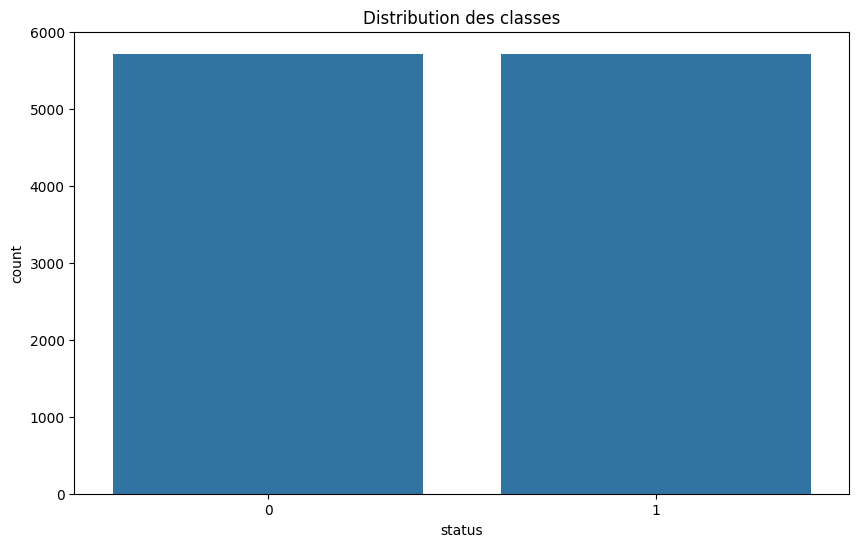

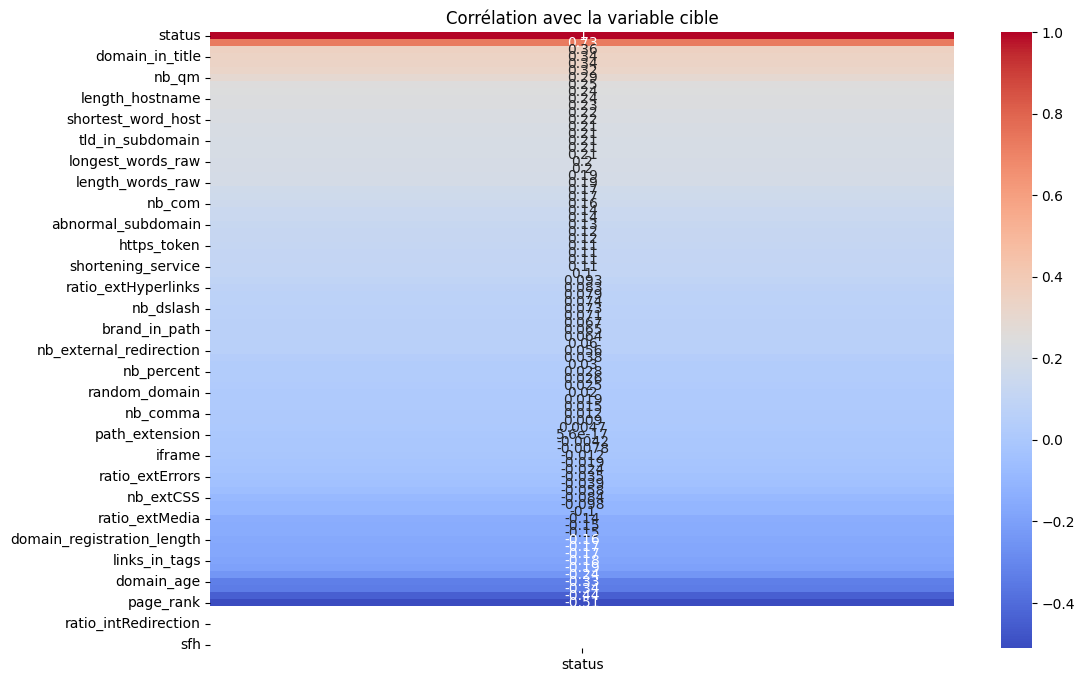

Distribution après SMOTE : [5709 5709]
[0]	train-logloss:0.61810	eval-logloss:0.61754
[1]	train-logloss:0.55689	eval-logloss:0.55583
[2]	train-logloss:0.50547	eval-logloss:0.50457
[3]	train-logloss:0.46212	eval-logloss:0.46104
[4]	train-logloss:0.42448	eval-logloss:0.42306
[5]	train-logloss:0.39237	eval-logloss:0.39089
[6]	train-logloss:0.36372	eval-logloss:0.36253
[7]	train-logloss:0.33830	eval-logloss:0.33750
[8]	train-logloss:0.31601	eval-logloss:0.31599
[9]	train-logloss:0.29601	eval-logloss:0.29665
[10]	train-logloss:0.27870	eval-logloss:0.28025
[11]	train-logloss:0.26219	eval-logloss:0.26437
[12]	train-logloss:0.24840	eval-logloss:0.25151
[13]	train-logloss:0.23578	eval-logloss:0.23970
[14]	train-logloss:0.22473	eval-logloss:0.22939
[15]	train-logloss:0.21461	eval-logloss:0.22005
[16]	train-logloss:0.20557	eval-logloss:0.21112
[17]	train-logloss:0.19628	eval-logloss:0.20293
[18]	train-logloss:0.18881	eval-logloss:0.19580
[19]	train-logloss:0.18199	eval-logloss:0.18992
[20]	train-

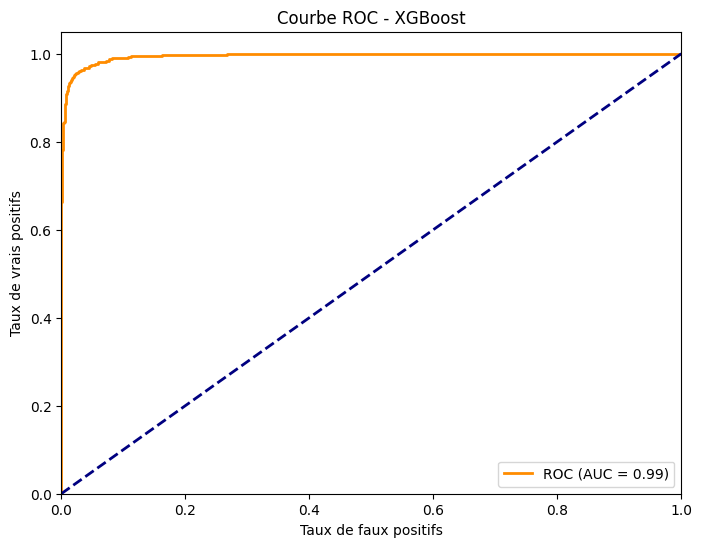

In [ ]:
# ---------------------------
# 1. Importation des librairies nécessaires
# ---------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

from sklearn.ensemble import IsolationForest
from imblearn.over_sampling import SMOTE

import xgboost as xgb

# ---------------------------
# 2. Chargement et préparation des données
# ---------------------------
# Chargement du dataset
df = pd.read_csv("dataset_phishing.csv")

# Suppression de la colonne non pertinente et encodage de la variable cible
df = df.drop(columns=['url'])
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})
df.dropna(subset=['status'], inplace=True)

# Visualisation exploratoire (optionnel)
plt.figure(figsize=(10, 6))
sns.countplot(x='status', data=df)
plt.title('Distribution des classes')
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr()[['status']].sort_values('status', ascending=False),
            annot=True, cmap='coolwarm')
plt.title('Corrélation avec la variable cible')
plt.show()

# Séparation des features et de la target
X = df.drop(columns=['status']).values
y = df['status'].values

# ---------------------------
# 3. Normalisation des features
# ---------------------------
scaler = StandardScaler()
X = scaler.fit_transform(X)

# ---------------------------
# 4. Suppression des anomalies avec IsolationForest
# ---------------------------
chosen_contamination = 0.01  # Taux de contamination choisi
iso = IsolationForest(contamination=chosen_contamination, random_state=42)
pred_anomalies = iso.fit_predict(X)
mask = pred_anomalies != -1  # Conserver les échantillons jugés normaux

X = X[mask]
y = y[mask]

# ---------------------------
# 5. Équilibrage de la dataset avec SMOTE
# ---------------------------
smote = SMOTE(random_state=42)
X, y = smote.fit_resample(X, y)
print("Distribution après SMOTE :", np.bincount(y))

# ---------------------------
# 6. Split train/test
# ---------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# ---------------------------
# 7. Préparation des DMatrix pour XGBoost
# ---------------------------
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest  = xgb.DMatrix(X_test, label=y_test)

# ---------------------------
# 8. Définition des paramètres XGBoost et entraînement via xgb.train
# ---------------------------
params = {
    'objective': 'binary:logistic',
    'eval_metric': 'logloss',
    'max_depth': 5,
    'eta': 0.1,        # Taux d'apprentissage
    'seed': 42
}

evals = [(dtrain, 'train'), (dtest, 'eval')]

# Entraînement avec early stopping (arrêt si pas d'amélioration pendant 10 itérations)
num_boost_round = 100
bst = xgb.train(params,
                dtrain,
                num_boost_round=num_boost_round,
                evals=evals,
                early_stopping_rounds=10,
                verbose_eval=True)

# ---------------------------
# 9. Prédictions et évaluation du modèle
# ---------------------------
# Prédiction des probabilités sur le jeu de test
y_proba = bst.predict(dtest)

# Application d'un seuil de 0.5 pour obtenir les classes prédictes
y_pred = (y_proba >= 0.5).astype(int)

print("\n--- Rapport de classification (XGBoost) ---")
print(classification_report(y_test, y_pred))

# Calcul de la courbe ROC et AUC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Courbe ROC - XGBoost')
plt.legend(loc="lower right")
plt.show()
